# Experiment 2 
## Optimal sliding window size
#### Synthetic data


In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.imports import *
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_synthetic
from src.utils import setup_latex_plotting

All imports are fine


### Load data

In [2]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])

### Fit RidgeSig (EFM sig) on different data sets
For each smoothing parameter, simulate a synthetic data set of electricity demand. For each dataset, fit a ridge regression model on sliding-window signature features, varying the window size (with the added option of varying the truncation order).

In [3]:
smooth_params = [0.005, 0.05]
sd = 500

delay_days = 2  
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
lambdas = np.logspace(-3, 3, 50)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
trunc_orders = [5]
metric = "rmse"

lams_efm = np.linspace(10,40,20) #np.log(2)/windows
 # lams_efm = np.linspace(10,20,5) #confiugure lambdas for EFM
n_lams = lams_efm.shape[0]
print(lams_efm)
consumption_sim = np.empty((len(smooth_params), len(consumption)))
error_alpha_efm   = np.empty((len(smooth_params), len(trunc_orders), n_lams))


for i, alpha in enumerate(smooth_params):
    # Simulate consumption for different smoothing parameters
    consumption_sim[i, :] = consumption_simulate(
        df, sd, smooth_param=alpha, fixed_seed=141
    )

    for j, d in enumerate(trunc_orders):
        for k, lam in enumerate(lams_efm):
            print(f'processing for lambda efm : {lam}')
            result_efm = ridge_signatures(
                covariates=temp,
                target=consumption_sim[i, :],
                window=0, # not needed for EFM
                delay=delay,
                n_train=n_train,
                n_valid=n_valid,
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=True,
                metric=metric,
                signature_type='efm',
                lam = np.array([lam]), # EFM lambda is taken as constant
                max_window=max(windows) # window taken for the convergence of EFM 
            )
            error_alpha_efm[i, j, k] = result_efm["error_test"]


[10.         11.57894737 13.15789474 14.73684211 16.31578947 17.89473684
 19.47368421 21.05263158 22.63157895 24.21052632 25.78947368 27.36842105
 28.94736842 30.52631579 32.10526316 33.68421053 35.26315789 36.84210526
 38.42105263 40.        ]
processing for lambda efm : 10.0
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 2.07 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
processing for lambda efm : 11.578947368421053
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 0.22 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
processing for lambda efm : 13.157894736842106
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 

### Plots 
For each smoothing parameter, plot the error metric chosen above against different window sizes.

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

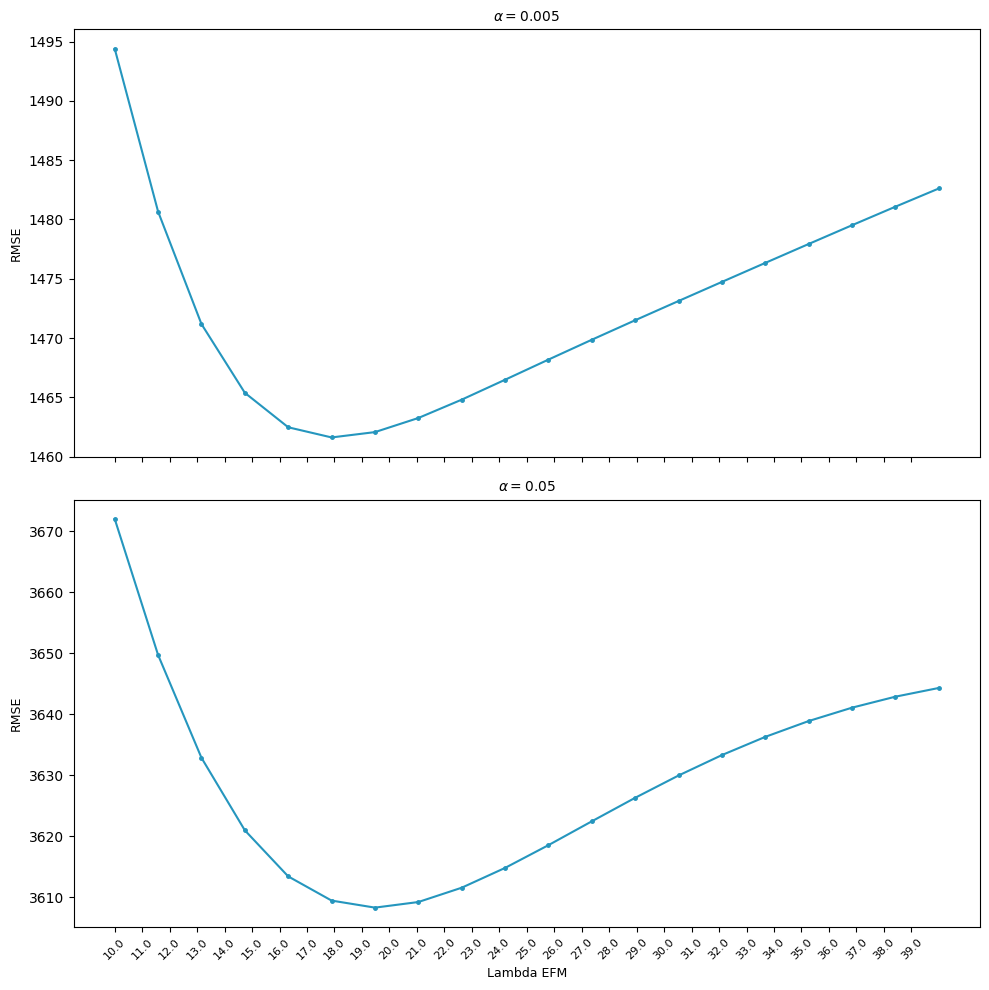

In [4]:
n_trunc = len(trunc_orders)
cmap = mpl.colormaps["viridis"].resampled(n_trunc)  
colors = [cmap(i) for i in range(n_trunc)]
colors.insert(0,"#2596be")

setup_latex_plotting()


xticks = np.arange(lams_efm[0], lams_efm[-1])
xticklabels = xticks

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharex=True)

for i, alpha in enumerate(smooth_params[:2]):  
    ax = axes[i]
    for j, d in enumerate(trunc_orders):
        ax.plot(
            lams_efm,
            error_alpha_efm[i, j],
            marker='.',
            markersize=5,
            color=colors[j],
            #label=f"Truncation order = {d}"
        )
    ax.set_ylabel(metric.upper(),fontsize=9)
    # ax.legend(fontsize=9)
    ax.set_title(rf"$\alpha = {alpha}$",fontsize=10)

axes[-1].set_xticks(xticks)
axes[-1].set_xticklabels(xticklabels)
axes[-1].tick_params(axis='x', labelrotation=45,labelsize=8)
axes[-1].set_xlabel("Lambda EFM",fontsize=9)

plt.tight_layout()
plt.show()
